In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
#1) Loading the Taxis Dataset

In [6]:
df = sns.load_dataset("taxis")

In [7]:
# 2) Handling Missing Values
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())


Missing values per column:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [9]:
# Impute missing numerical values using median
df['pickup_borough'] = df['pickup_borough'].fillna(df['pickup_borough'].mode()[0])
df['dropoff_borough'] = df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0])
df['pickup_zone'] = df['pickup_zone'].fillna(df['pickup_zone'].mode()[0])
df['dropoff_zone'] = df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0])
df['payment'] = df['payment'].fillna(df['payment'].mode()[0])


In [23]:
# Drop remaining rows with missing values (without inplace=True)
df = df.dropna()


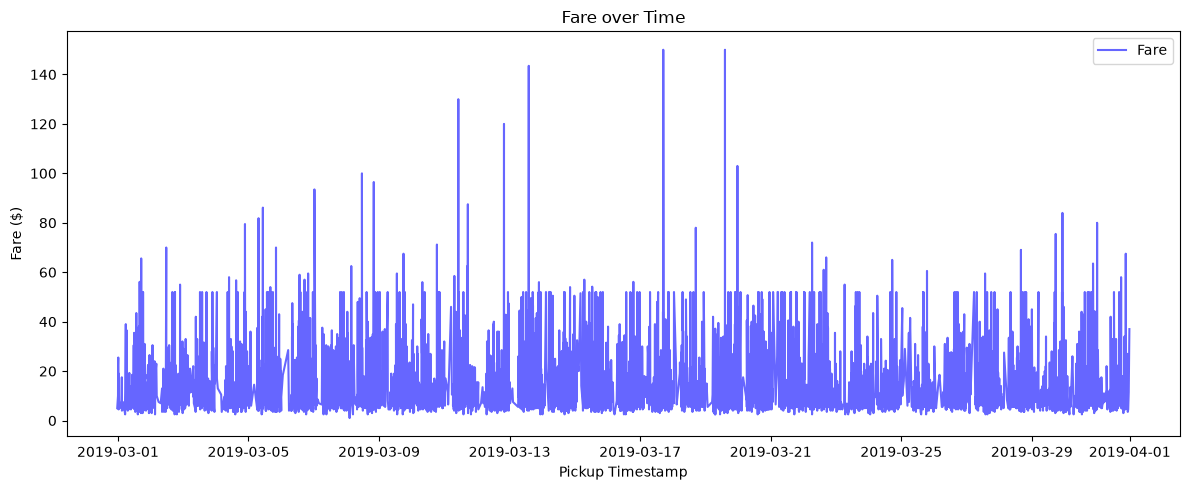

In [13]:
# 3) Visualizations using Matplotlib / Pandas
# Ensure datetime format for pickup and dropoff
df['pickup'] = pd.to_datetime(df['pickup'])
df['dropoff'] = pd.to_datetime(df['dropoff'])

# ★ Line Chart: Fare over time
plt.figure(figsize=(12, 5))
df_sorted = df.sort_values('pickup')
plt.plot(df_sorted['pickup'], df_sorted['fare'], label='Fare', color='blue', alpha=0.6)
plt.title('Fare over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare ($)')
plt.legend()
plt.tight_layout()
plt.show()

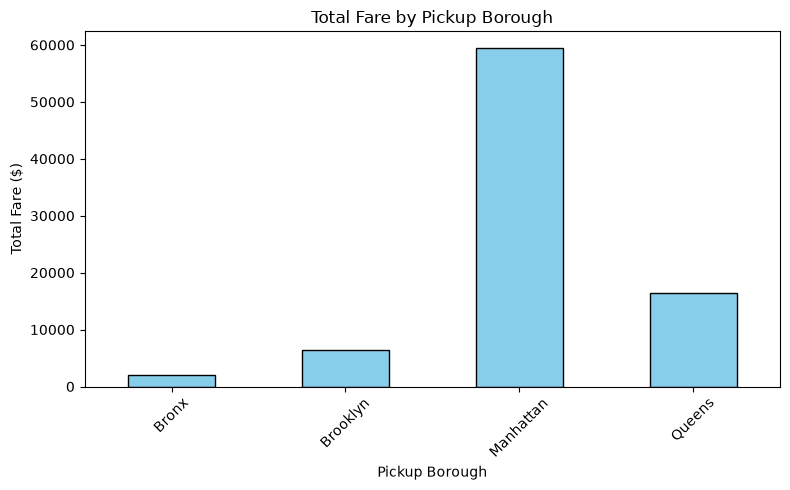

In [14]:
# ★ Bar Chart: Total fare by pickup_borough
plt.figure(figsize=(8, 5))
fare_by_borough = df.groupby('pickup_borough')['fare'].sum()
fare_by_borough.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

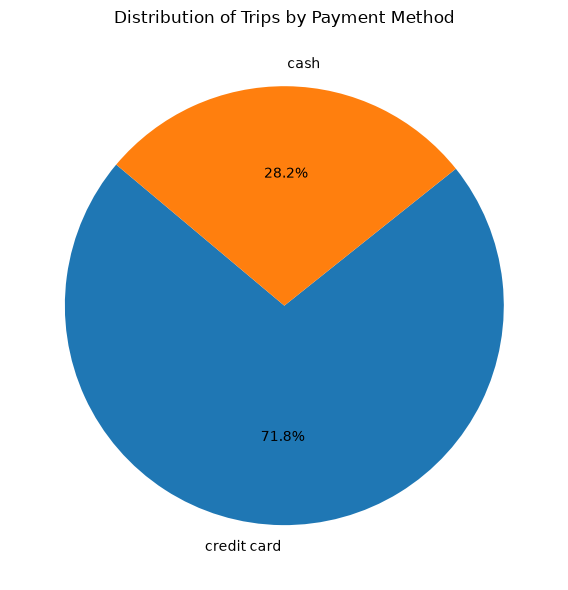

In [15]:
# ★ Pie Chart: Trip distribution by payment method
plt.figure(figsize=(6, 6))
payment_counts = df['payment'].value_counts()
plt.pie(payment_counts, labels=payment_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribution of Trips by Payment Method')
plt.tight_layout()
plt.show()

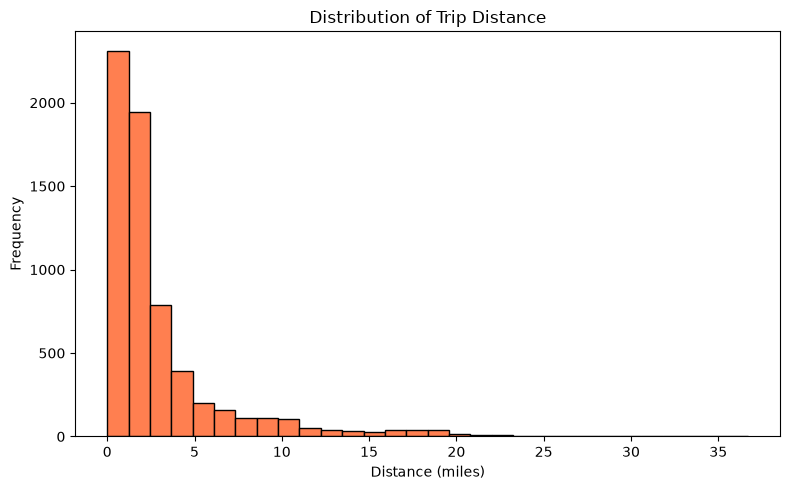

In [16]:
# ★ Histogram: Distribution of distance
plt.figure(figsize=(8, 5))
plt.hist(df['distance'], bins=30, color='coral', edgecolor='black')
plt.title('Distribution of Trip Distance')
plt.xlabel('Distance (miles)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

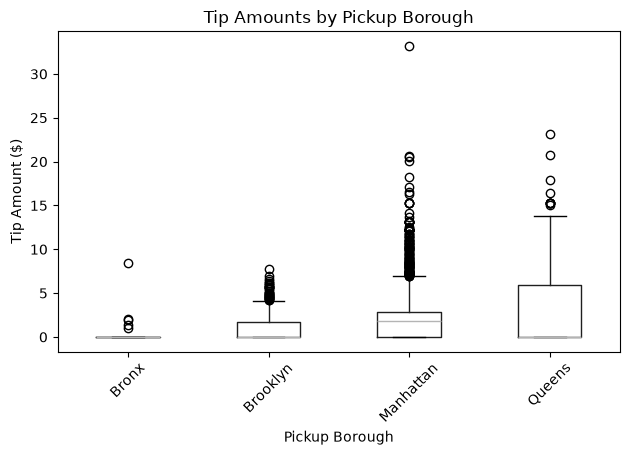

In [17]:
# ★ Box Plot: Tip amounts per pickup_borough
plt.figure(figsize=(8, 5))
df.boxplot(column='tip', by='pickup_borough', grid=False)
plt.title('Tip Amounts by Pickup Borough')
plt.suptitle('')  # Clear default title
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_65464\2589998865.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='pickup_borough', palette='viridis')


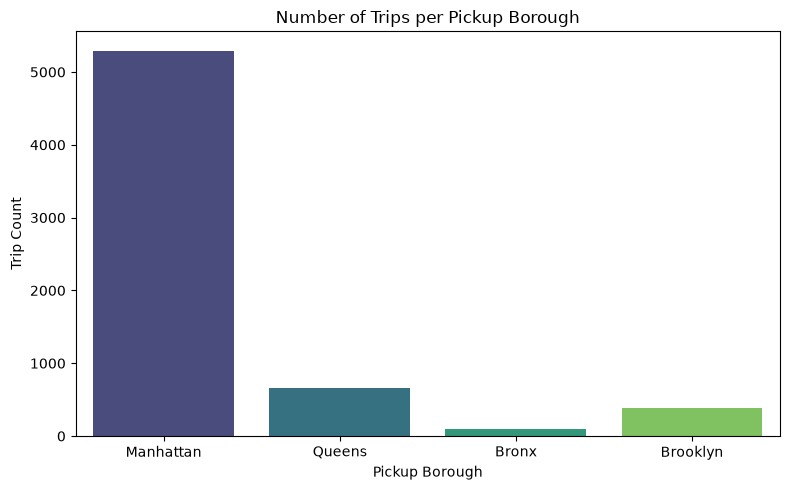

In [18]:
 #4) Visualizations using Seaborn

 # ★ Count Plot: Number of trips in each pickup_borough
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='pickup_borough', palette='viridis')
plt.title('Number of Trips per Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Trip Count')
plt.tight_layout()
plt.show()

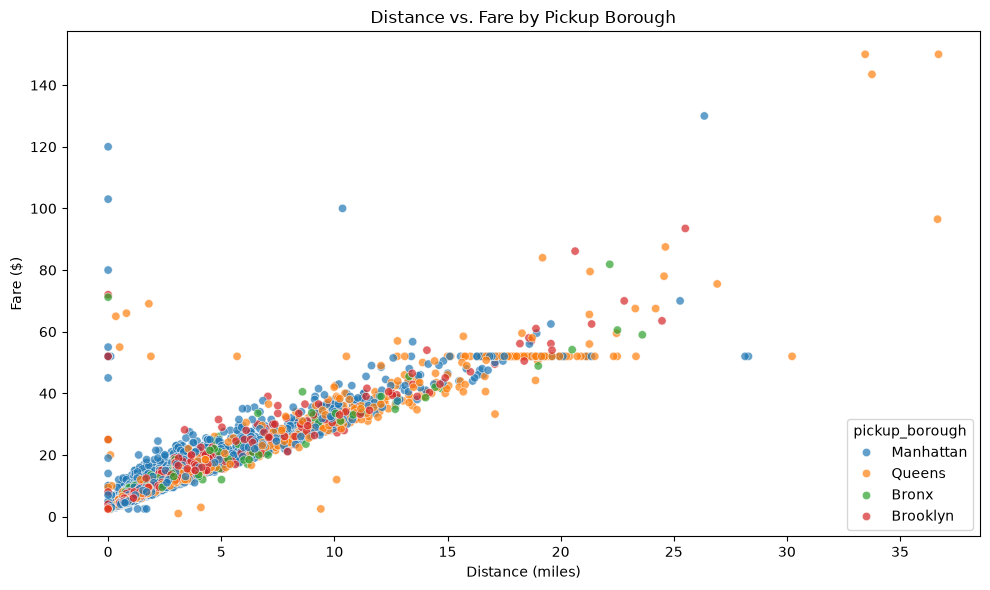

In [19]:
# ★ Scatter Plot: Distance vs. Fare colored by pickup_borough
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='distance', y='fare', hue='pickup_borough', alpha=0.7)
plt.title('Distance vs. Fare by Pickup Borough')
plt.xlabel('Distance (miles)')
plt.ylabel('Fare ($)')
plt.tight_layout()
plt.show()

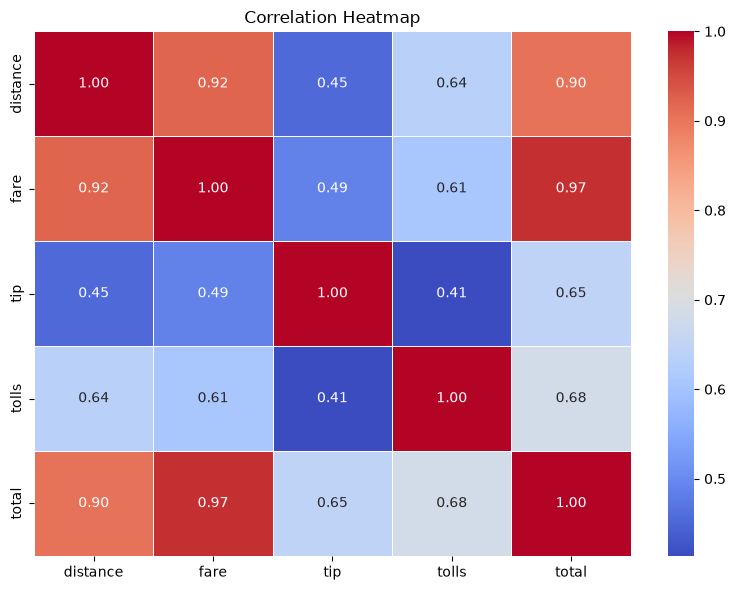

In [20]:
# ★ Heatmap: Correlation matrix between numerical variables
plt.figure(figsize=(8, 6))
numeric_cols = ['distance', 'fare', 'tip', 'tolls', 'total']
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

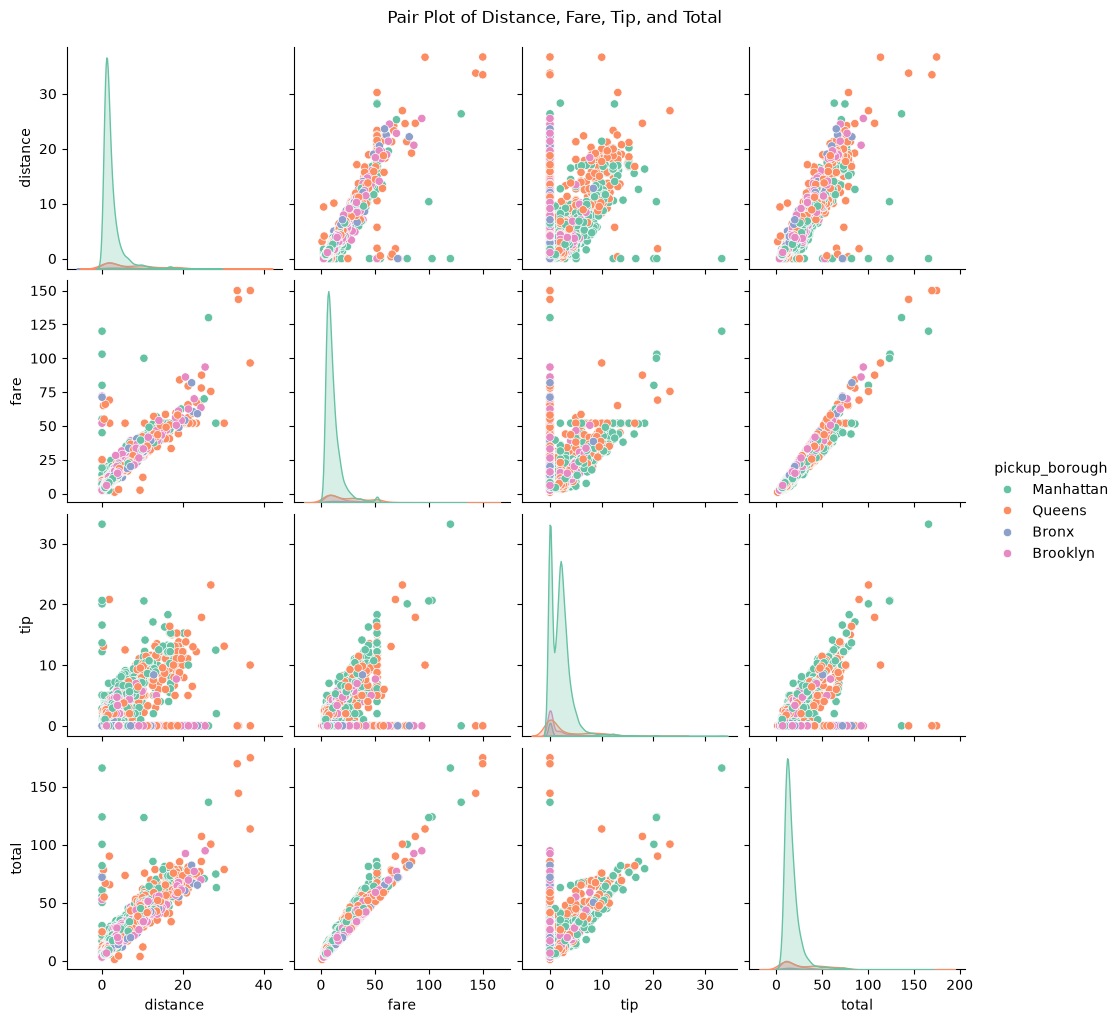

In [21]:
# ★ Pair Plot: Relationships between key metrics colored by pickup_zone/borough
sns.pairplot(df, vars=['distance', 'fare', 'tip', 'total'], hue='pickup_borough', palette='Set2')
plt.suptitle('Pair Plot of Distance, Fare, Tip, and Total', y=1.02)
plt.show()


C:\Users\HP\AppData\Local\Temp\ipykernel_65464\588092550.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='payment', y='fare', palette='muted')


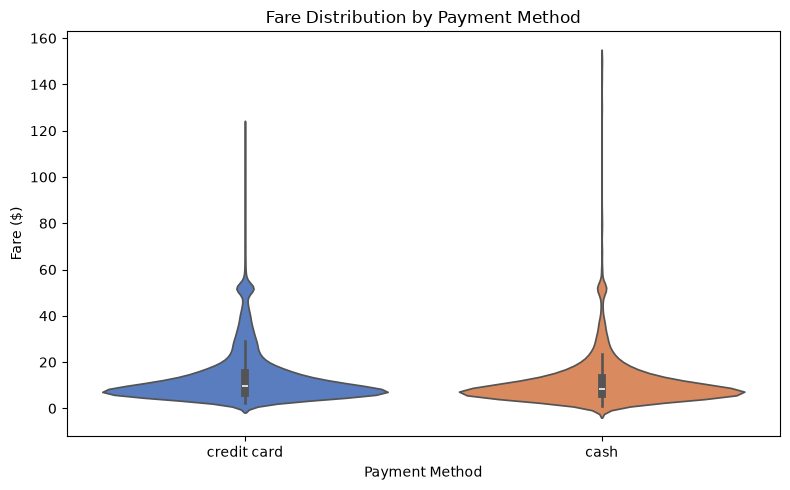

In [22]:
# ★ Violin Plot: Distribution of fare for each payment method
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x='payment', y='fare', palette='muted')
plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare ($)')
plt.tight_layout()
plt.show()